# Analyse de Clustering sur le Dataset Iris

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Chargement et Exploration Initiale des Données

In [ ]:
import pandas as pd
df=pd.read_csv('/content/drive/MyDrive/DataMining/Iris.csv')

### Question 1.1: Comment charger le dataset Iris?

In [ ]:
print(df)

      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  Species
0      1            5.1           3.5            1.4           0.2        0
1      2            4.9           3.0            1.4           0.2        0
2      3            4.7           3.2            1.3           0.2        0
3      4            4.6           3.1            1.5           0.2        0
4      5            5.0           3.6            1.4           0.2        0
..   ...            ...           ...            ...           ...      ...
145  146            6.7           3.0            5.2           2.3        2
146  147            6.3           2.5            5.0           1.9        2
147  148            6.5           3.0            5.2           2.0        2
148  149            6.2           3.4            5.4           2.3        2
149  150            5.9           3.0            5.1           1.8        2

[150 rows x 6 columns]


### Question 1.2: Quelles sont les premières lignes du DataFrame et ses statistiques descriptives?

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

### Question 1.3: Comment visualiser la distribution des sépales en fonction de l'espèce?

In [ ]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667,1.000000
std,43.445368,0.828066,0.433594,1.764420,0.763161,0.819232
min,1.000000,4.300000,2.000000,1.000000,0.100000,0.000000
25%,38.250000,5.100000,2.800000,1.600000,0.300000,0.000000
50%,75.500000,5.800000,3.000000,4.350000,1.300000,1.000000
75%,112.750000,6.400000,3.300000,5.100000,1.800000,2.000000
max,150.000000,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,0
1,2,4.9,3.0,1.4,0.2,0
2,3,4.7,3.2,1.3,0.2,0
3,4,4.6,3.1,1.5,0.2,0
4,5,5.0,3.6,1.4,0.2,0


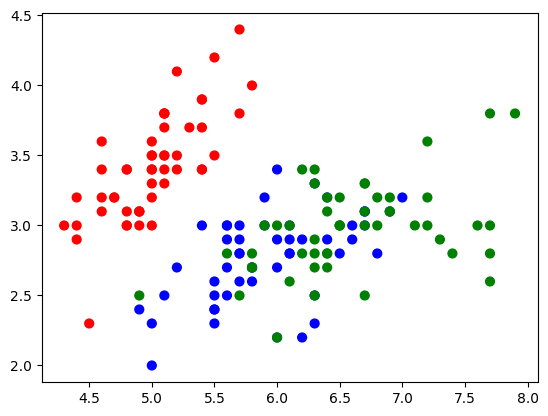

In [ ]:
colorMap = np.array(["red", "blue","green"])
plt.scatter(df["SepalLengthCm"], df["SepalWidthCm"], c=colorMap[df["Species"]], s=40)

In [ ]:
x = df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
y = df["Species"]

print(x)
print(y)

     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0              5.1           3.5            1.4           0.2
1              4.9           3.0            1.4           0.2
2              4.7           3.2            1.3           0.2
3              4.6           3.1            1.5           0.2
4              5.0           3.6            1.4           0.2
..             ...           ...            ...           ...
145            6.7           3.0            5.2           2.3
146            6.3           2.5            5.0           1.9
147            6.5           3.0            5.2           2.0
148            6.2           3.4            5.4           2.3
149            5.9           3.0            5.1           1.8

[150 rows x 4 columns]
0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: Species, Length: 150, dtype: int64


### Question 1.4: Comment préparer les données (features et labels) pour le clustering?

In [ ]:
initial_centers = np.array([[5.88360656, 2.74098361, 4.38852459, 1.43442623],
                            [5.006,      3.418,      1.464,      0.244     ],
                            [6.85384615, 3.07692308, 5.71538462, 2.05384615]])

### Question 2.1: Comment appliquer K-Means avec des centres initiaux spécifiques?

In [ ]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=3, init=initial_centers, n_init=1, random_state=42)
model.fit(x)

KMeans(init=array([[5.88360656, 2.74098361, 4.38852459, 1.43442623],
       [5.006     , 3.418     , 1.464     , 0.244     ],
       [6.85384615, 3.07692308, 5.71538462, 2.05384615]]),
       n_clusters=3, n_init=1, random_state=42)

### Question 2.2: Quels sont les labels de cluster attribués et les centres de cluster résultants?

In [ ]:
print(model.labels_)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [ ]:
print(model.cluster_centers_)

[[5.88360656 2.74098361 4.38852459 1.43442623]
 [5.006      3.418      1.464      0.244     ]
 [6.85384615 3.07692308 5.71538462 2.05384615]]


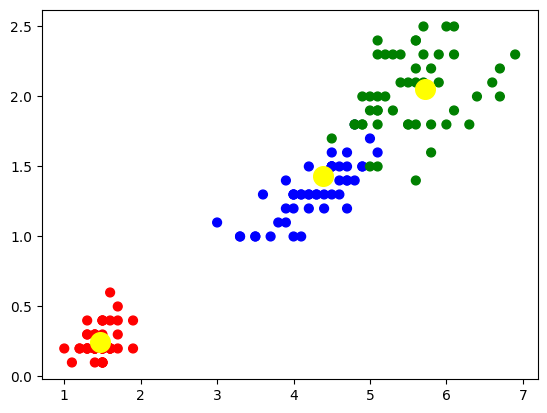

In [ ]:
plt.scatter(df["PetalLengthCm"],df["PetalWidthCm"], c=colorMap[df["Species"]], s=40)
plt.scatter(model.cluster_centers_[:,2],model.cluster_centers_[:,3],c="yellow",s=200)

### Question 2.3: Comment visualiser les clusters K-Means pour les pétales?

In [ ]:
y

,Species
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [ ]:
print(model.labels_)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [ ]:
predY = np.choose(model.labels_, [1,0,2]).astype(np.int64)
print(predY)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 2 2 2
 2 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 2 2 2 2 2 1 2 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]


### Question 2.4: Quelle est la précision et la matrice de confusion du modèle K-Means initial?

In [ ]:
from sklearn import metrics as sm

print("Accuracy :", sm.accuracy_score(y, predY))
print("Matrice de confusion :")
print(sm.confusion_matrix(y, predY))

Accuracy : 0.8866666666666667
Matrice de confusion :
[[50  0  0]
 [ 0 47  3]
 [ 0 14 36]]


## 2. Clustering K-Means

In [ ]:
from sklearn.cluster import KMeans
from sklearn import metrics as sm
import numpy as np

accuracies = []
confusion_matrices = []
inertias = []

for i in range(10):
    print(f"\n--- KMeans Run {i+1} ---")

    model_run = KMeans(n_clusters=3, n_init=10, random_state=None) # n_init=10 for robustness
    model_run.fit(x)

    predY_run = np.choose(model_run.labels_, [1,0,2]).astype(np.int64)

    accuracy = sm.accuracy_score(y, predY_run)
    confusion = sm.confusion_matrix(y, predY_run)
    inertia = model_run.inertia_

    accuracies.append(accuracy)
    confusion_matrices.append(confusion)
    inertias.append(inertia)

    print(f"Accuracy : {accuracy}")
    print(f"Matrice de confusion :\n{confusion}")
    print(f"Inertia : {inertia:.2f}")

print("\n--- Comparison of all 10 runs ---")
for i, acc in enumerate(accuracies):
    print(f"Run {i+1}: Accuracy = {acc:.4f}, Inertia = {inertias[i]:.2f}")
    print(f"           Confusion Matrix =\n{confusion_matrices[i]}")



--- KMeans Run 1 ---
Accuracy : 0.44
Matrice de confusion :
[[50  0  0]
 [ 0  2 48]
 [ 0 36 14]]
Inertia : 78.94

--- KMeans Run 2 ---
Accuracy : 0.8933333333333333
Matrice de confusion :
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]
Inertia : 78.94

--- KMeans Run 3 ---
Accuracy : 0.8933333333333333
Matrice de confusion :
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]
Inertia : 78.94

--- KMeans Run 4 ---
Accuracy : 0.8933333333333333
Matrice de confusion :
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]
Inertia : 78.94

--- KMeans Run 5 ---
Accuracy : 0.24
Matrice de confusion :
[[ 0 50  0]
 [48  0  2]
 [14  0 36]]
Inertia : 78.94

--- KMeans Run 6 ---
Accuracy : 0.44
Matrice de confusion :
[[50  0  0]
 [ 0  2 48]
 [ 0 36 14]]
Inertia : 78.94

--- KMeans Run 7 ---
Accuracy : 0.8933333333333333
Matrice de confusion :
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]
Inertia : 78.94

--- KMeans Run 8 ---
Accuracy : 0.8933333333333333
Matrice de confusion :
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]
Inertia : 78.94

--- KMeans Run 9 

### Question 2.5: Comment la robustesse de K-Means varie-t-elle sur plusieurs exécutions?

In [ ]:
print("\n--- Varying max_iter for KMeans ---")

max_iter_values = [1,  50, 100, 500]

for max_it in max_iter_values:
    print(f"\nRunning KMeans with max_iter = {max_it}")

    model_max_iter = KMeans(n_clusters=3, n_init=10, max_iter=max_it, random_state=42)
    model_max_iter.fit(x)

    print(f"Inertia for max_iter {max_it}: {model_max_iter.inertia_:.2f}")

print("\nObservations on max_iter:")
print("You should observe that for a certain number of iterations, the inertia converges to a stable minimum value. Increasing max_iter beyond this point usually doesn't change the inertia significantly, as the algorithm has already found a stable solution. If max_iter is too low, the algorithm might stop prematurely before reaching convergence, leading to a higher inertia.")


--- Varying max_iter for KMeans ---

Running KMeans with max_iter = 1
Inertia for max_iter 1: 78.95

Running KMeans with max_iter = 50
Inertia for max_iter 50: 78.94

Running KMeans with max_iter = 100
Inertia for max_iter 100: 78.94

Running KMeans with max_iter = 500
Inertia for max_iter 500: 78.94

Observations on max_iter:
You should observe that for a certain number of iterations, the inertia converges to a stable minimum value. Increasing max_iter beyond this point usually doesn't change the inertia significantly, as the algorithm has already found a stable solution. If max_iter is too low, the algorithm might stop prematurely before reaching convergence, leading to a higher inertia.


### Question 2.6: Quel est l'impact de `max_iter` sur la convergence de K-Means?

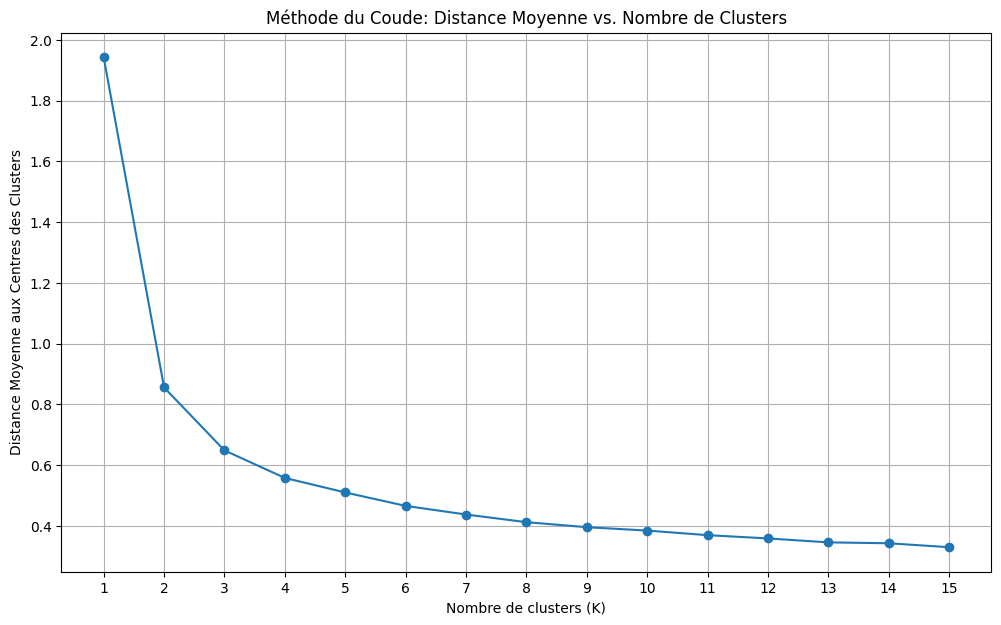

Liste des distances moyennes pour chaque K : [np.float64(1.943034159037026), np.float64(0.8560279682448629), np.float64(0.6488394948953341), np.float64(0.5581937771352218), np.float64(0.5104611995137194), np.float64(0.4661766694572027), np.float64(0.43783364259799046), np.float64(0.41257004250331863), np.float64(0.39608193470771175), np.float64(0.38492527170180635), np.float64(0.3698475972818522), np.float64(0.3590514004130224), np.float64(0.3460906234188266), np.float64(0.343158467147119), np.float64(0.3301235182455295)]


In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import numpy as np

AvgDist_List = []
max_k = 15

for k in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x)

    distances_matrix = cdist(x, kmeans.cluster_centers_, 'euclidean')
    distances_to_assigned_centers = [distances_matrix[i, kmeans.labels_[i]] for i in range(len(x))]
    average_distance_for_k = np.mean(distances_to_assigned_centers)

    AvgDist_List.append(average_distance_for_k)

plt.figure(figsize=(12, 7))
plt.plot(range(1, max_k + 1), AvgDist_List, marker='o')
plt.title('Méthode du Coude: Distance Moyenne vs. Nombre de Clusters')
plt.xlabel('Nombre de clusters (K)')
plt.ylabel('Distance Moyenne aux Centres des Clusters')
plt.xticks(range(1, max_k + 1))
plt.grid(True)
plt.show()

print("Liste des distances moyennes pour chaque K :", AvgDist_List)

### Question 2.7: Comment déterminer le nombre optimal de clusters K en utilisant la méthode du coude (Elbow Method)?

In [ ]:

x_sepals = df[['SepalLengthCm', 'SepalWidthCm']]

print(x_sepals.head())


   SepalLengthCm  SepalWidthCm
0            5.1           3.5
1            4.9           3.0
2            4.7           3.2
3            4.6           3.1
4            5.0           3.6


In [ ]:
from sklearn.cluster import KMeans

x_sepals = df[['SepalLengthCm', 'SepalWidthCm']]

print("Nouvel ensemble de fonctionnalités (x_sepals):")
print(x_sepals.head())
model_sepals = KMeans(n_clusters=3, random_state=42, n_init=10)
model_sepals.fit(x_sepals)


print(model_sepals.labels_)
print(f"Inertia : {inertia:.2f}")


Nouvel ensemble de fonctionnalités (x_sepals):
   SepalLengthCm  SepalWidthCm
0            5.1           3.5
1            4.9           3.0
2            4.7           3.2
3            4.6           3.1
4            5.0           3.6
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 1 0 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1
 0 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0
 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 0 1 0
 0 1]
Inertia : 78.94


Précision de la segmentation avec les sépales: 0.8200
Matrice de confusion de la segmentation avec les sépales:
[[50  0  0]
 [ 0 38 12]
 [ 0 15 35]]


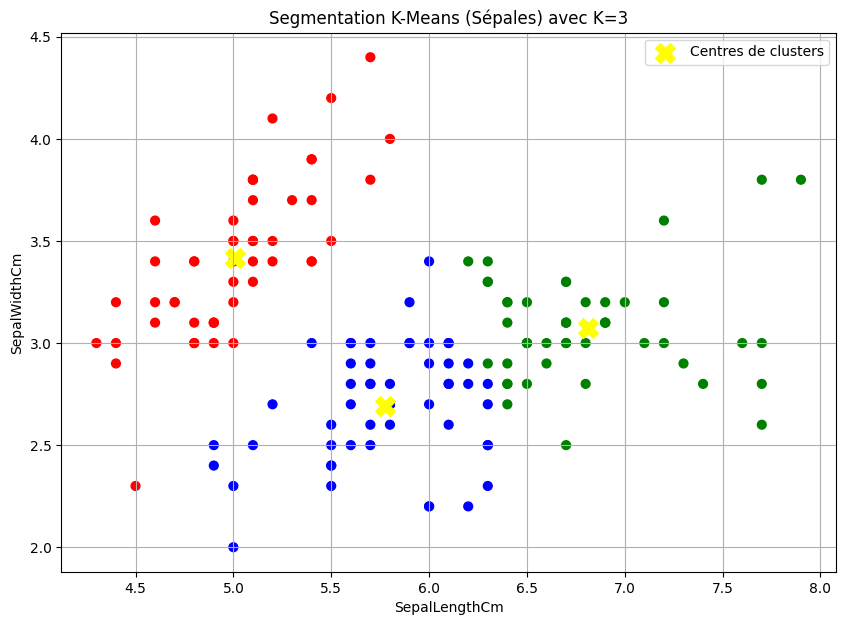

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics as sm
from itertools import permutations

def find_best_mapping(true_labels, predicted_labels, n_clusters):
    best_accuracy = 0
    best_permutation = None

    for perm in permutations(range(n_clusters)):
        mapped_predicted_labels = np.array([perm[label] for label in predicted_labels])
        current_accuracy = sm.accuracy_score(true_labels, mapped_predicted_labels)
        if current_accuracy > best_accuracy:
            best_accuracy = current_accuracy
            best_permutation = perm

    if best_permutation is None:

        best_predicted_labels = predicted_labels
    else:
        best_predicted_labels = np.array([best_permutation[label] for label in predicted_labels])

    return best_predicted_labels, best_accuracy

predY_sepals_mapped, accuracy_sepals = find_best_mapping(y, model_sepals.labels_, n_clusters=3)

print(f"Précision de la segmentation avec les sépales: {accuracy_sepals:.4f}")
print("Matrice de confusion de la segmentation avec les sépales:")
confusion_matrix_sepals = sm.confusion_matrix(y, predY_sepals_mapped)
print(confusion_matrix_sepals)

plt.figure(figsize=(10, 7))
plt.scatter(x_sepals['SepalLengthCm'], x_sepals['SepalWidthCm'], c=colorMap[predY_sepals_mapped], s=40)
plt.scatter(model_sepals.cluster_centers_[:,0], model_sepals.cluster_centers_[:,1], c='yellow', s=200, marker='X', label='Centres de clusters')
plt.title('Segmentation K-Means (Sépales) avec K=3')
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.legend()
plt.grid(True)
plt.show()

### Question 2.8: Comment la segmentation K-Means fonctionne-t-elle en utilisant uniquement les features de sépales?

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage,fcluster


Z = linkage(x, 'ward')
lables= fcluster(Z, 2, criterion='maxclust')



[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


## 3. Clustering Hiérarchique

In [ ]:
from sklearn.metrics import silhouette_score
best_score=0
best_k = 1
for k in range(2,10):
  lables= fcluster(Z, k, criterion='maxclust')
  score=silhouette_score(x,lables)
  if score>best_score:
    best_score = score
    best_k = k
print(lables)
print(best_score)
print(best_k)

[2 1 1 1 2 2 1 2 1 1 2 1 1 1 2 2 2 2 2 2 2 2 1 2 1 1 2 2 2 1 1 2 2 2 1 1 2
 1 1 2 2 1 1 2 2 1 2 1 2 2 8 9 8 6 8 6 9 5 8 6 5 9 6 9 6 8 6 6 7 6 9 9 7 9
 9 8 8 3 9 6 6 6 6 7 6 9 8 7 6 6 6 9 6 5 6 6 6 9 5 6 3 7 4 3 3 4 6 4 3 4 3
 3 3 7 7 3 3 4 4 7 3 7 4 7 3 4 7 9 3 4 4 4 3 7 7 4 3 3 9 3 3 3 7 3 3 3 7 3
 3 9]
0.6863930543445408
2


### Question 3.1: Comment créer un dendrogramme pour visualiser le clustering hiérarchique et identifier le nombre de clusters?

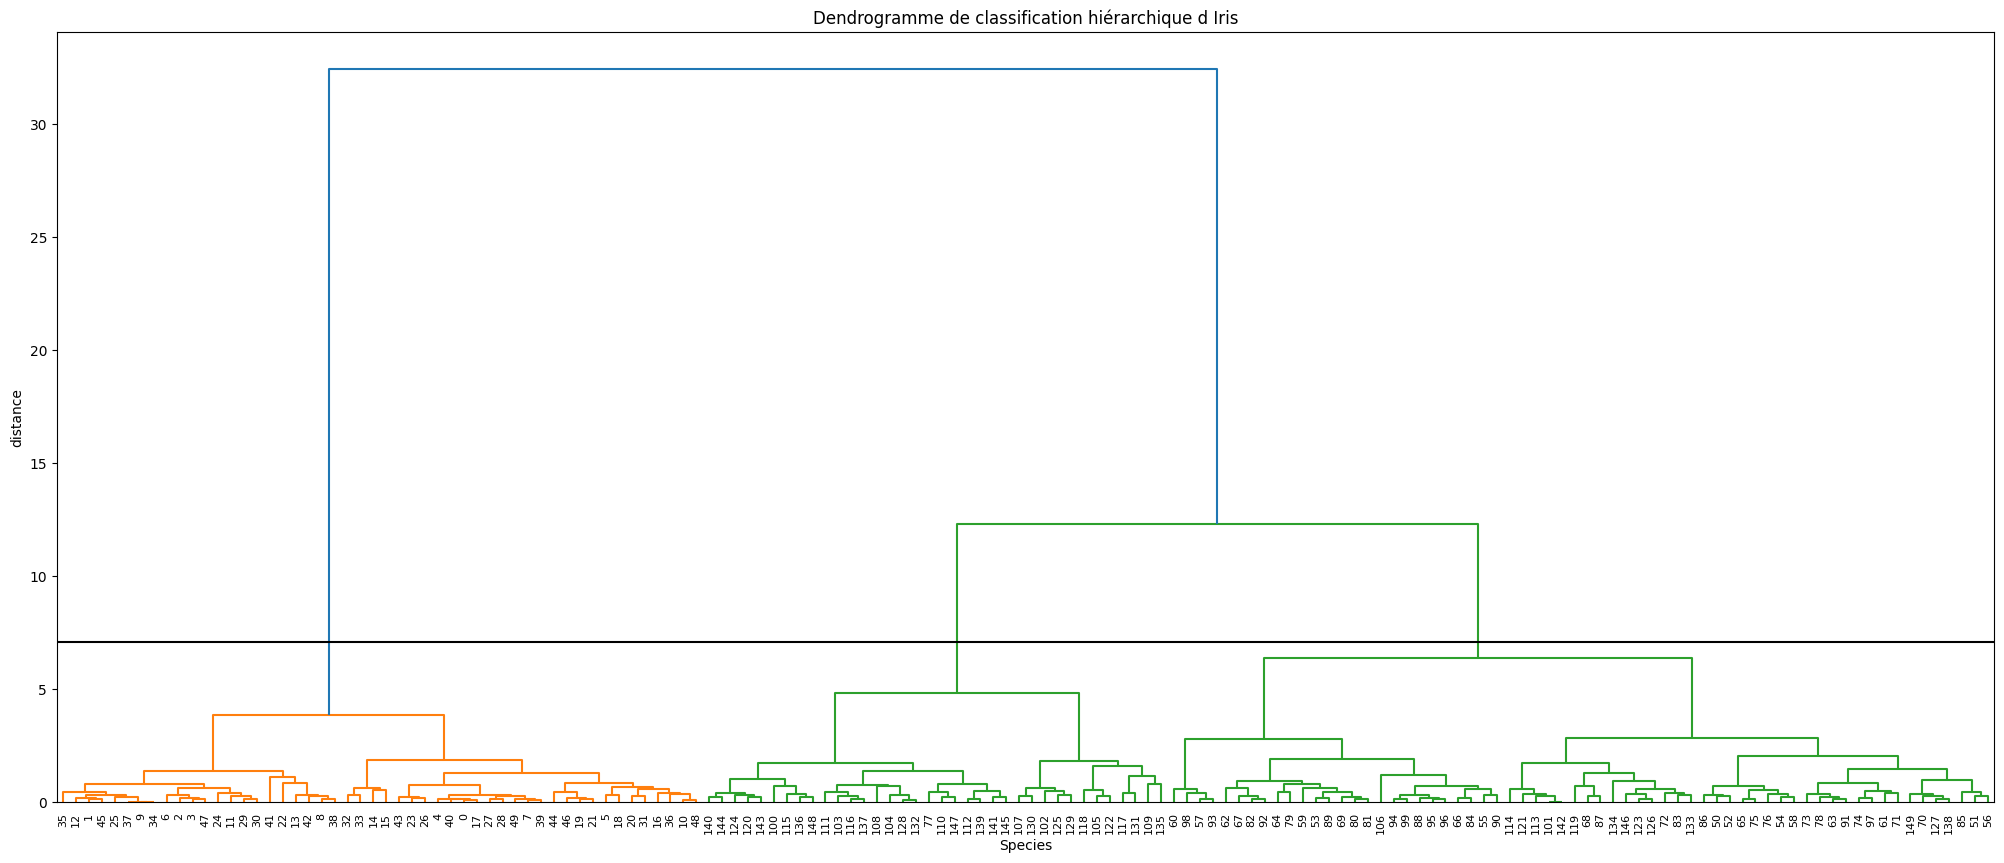

In [ ]:
max_d = 7.08
plt.figure(figsize=(25, 10))
plt.title('Dendrogramme de classification hiérarchique d Iris')
plt.xlabel('Species')
plt.ylabel('distance')
dendrogram(Z,truncate_mode='lastp',
p=150,
leaf_rotation=90.,
leaf_font_size=8.,
)
plt.axhline(y=max_d, c='k')
plt.show()

### Question 3.2: Comment évaluer la qualité du clustering hiérarchique à l'aide du score de silhouette avec différentes métriques de distance?

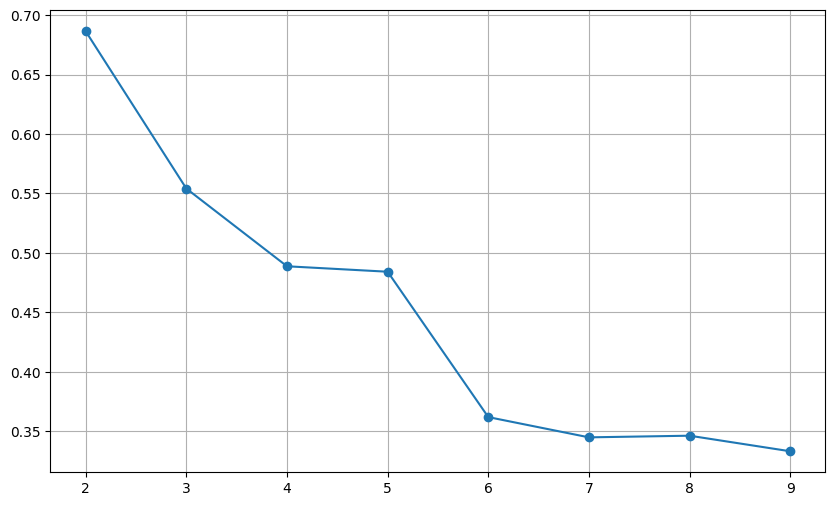

In [ ]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

best_score=0
best_k = 1
list_t=[]
liste_score=[]
for k in range(2,10):
  lables= fcluster(Z, k, criterion='maxclust')
  score=silhouette_score(x,lables,metric='euclidean')
  list_t.append(k)
  liste_score.append(score)


plt.figure(figsize=(10, 6))
plt.plot(list_t, liste_score, marker='o')
plt.xticks(list_t)
plt.grid(True)
plt.show()
